In [1]:
!pip install -q ftfy regex tqdm scipy scikit-learn seaborn
!pip install -q git+https://github.com/openai/CLIP.git

import os
import scipy.io as sio
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm import tqdm
import clip

from google.colab import drive
drive.mount('/content/drive')

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device utilisé :", device)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
Device utilisé : cuda


Nombre d'images de test SVHN : 26032
Dimensions d'une image : (32, 32, 3)
Classes présentes : [0 1 2 3 4 5 6 7 8 9]


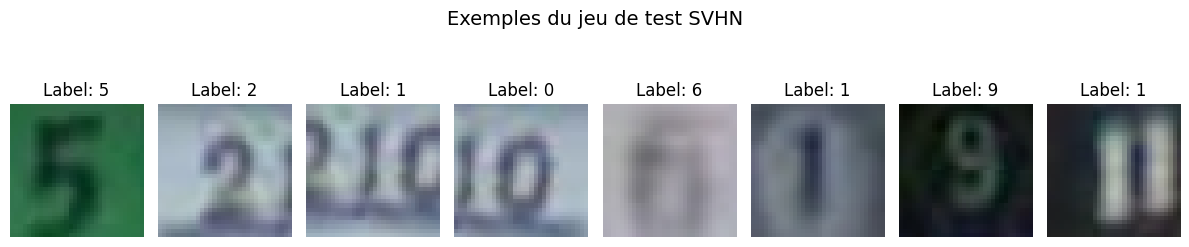

In [2]:
svhn_test_path = "/content/drive/MyDrive/svhn/test_32x32.mat"
mat_data = sio.loadmat(svhn_test_path)

# X a la forme (32, 32, 3, 26032) -> transposition en (26032, 32, 32, 3)
X_test = np.transpose(mat_data['X'], (3, 0, 1, 2))
# y a la forme (26032, 1) avec la classe 10 représentant le chiffre '0'
y_test = mat_data['y'].flatten()
y_test[y_test == 10] = 0

print(f"Nombre d'images de test SVHN : {X_test.shape[0]}")
print(f"Dimensions d'une image : {X_test.shape[1:]}")
print(f"Classes présentes : {np.unique(y_test)}")

# Affichage de quelques exemples du jeu de test
plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(X_test[i])
    plt.title(f"Label: {y_test[i]}")
    plt.axis("off")
plt.suptitle("Exemples du jeu de test SVHN", fontsize=14)
plt.tight_layout()
plt.show()

In [3]:
class SVHNMatDataset(Dataset):
    def __init__(self, images, labels, preprocess):
        self.images = images
        self.labels = labels
        self.preprocess = preprocess

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = Image.fromarray(self.images[idx])
        return self.preprocess(img), self.labels[idx]

def evaluate_clip_svhn(model_name, prompts, batch_size=256):
    model, preprocess = clip.load(model_name, device=device)
    model.eval()

    dataset = SVHNMatDataset(X_test, y_test, preprocess)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    # Encodage des prompts textuels pour les 10 chiffres (0 à 9)
    text_tokens = clip.tokenize(prompts).to(device)
    with torch.no_grad():
        text_features = model.encode_text(text_tokens).float()
        text_features /= text_features.norm(dim=-1, keepdim=True)

    all_preds = []
    all_probs = []

    with torch.no_grad():
        for images, _ in tqdm(loader, desc=f"Évaluation {model_name}", leave=False):
            images = images.to(device)
            image_features = model.encode_image(images).float()
            image_features /= image_features.norm(dim=-1, keepdim=True)

            # Logits CLIP (similarité cosinus * 100)
            logits = 100.0 * image_features @ text_features.T
            probs = logits.softmax(dim=-1)

            all_preds.append(probs.argmax(dim=-1).cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    y_pred = np.concatenate(all_preds)
    y_probs = np.concatenate(all_probs)

    top1_acc = accuracy_score(y_test, y_pred) * 100
    top3_acc = np.mean([y_test[i] in np.argsort(y_probs[i])[-3:] for i in range(len(y_test))]) * 100

    return top1_acc, top3_acc, y_pred, y_probs

In [5]:
import gc

if 'model' in globals():
    del model
gc.collect()
torch.cuda.empty_cache()

model_name = "ViT-B/16"

model, preprocess = clip.load(model_name, device=device)
model.eval()

# 1. Extraction légère des features images (batch_size=128, num_workers=0)
dataset = SVHNMatDataset(X_test, y_test, preprocess)
loader = DataLoader(dataset, batch_size=128, shuffle=False, num_workers=0)

all_img_features = []
with torch.no_grad():
    for images, _ in tqdm(loader, desc=f"Extraction features ({model_name})"):
        feats = model.encode_image(images.to(device))
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_img_features.append(feats.cpu())

image_features = torch.cat(all_img_features, dim=0).float()
del all_img_features
gc.collect()

# Évaluation des deux stratégies de prompts
classes = [str(i) for i in range(10)]
prompts_dict = {
    "Prompt Basique": [f"This is a photo of a {c}" for c in classes],
    "Prompt OpenAI (SVHN)": [f"a street sign of the number: '{c}'" for c in classes]
}

results = []
for prompt_label, prompt_list in prompts_dict.items():
    text_tokens = clip.tokenize(prompt_list).to(device)
    with torch.no_grad():
        text_features = model.encode_text(text_tokens).float()
        text_features /= text_features.norm(dim=-1, keepdim=True)
        text_features = text_features.cpu()

        logits = 100.0 * image_features @ text_features.T
        probs = logits.softmax(dim=-1).numpy()
        preds = probs.argmax(axis=-1)

    top1 = accuracy_score(y_test, preds) * 100
    top3 = np.mean([y_test[i] in np.argsort(probs[i])[-3:] for i in range(len(y_test))]) * 100

    results.append({
        "Modèle": model_name,
        "Stratégie de Prompt": prompt_label,
        "Accuracy Top-1 (%)": round(top1, 2),
        "Accuracy Top-3 (%)": round(top3, 2)
    })

    if prompt_label == "Prompt OpenAI (SVHN)":
        best_model_name = model_name
        best_preds = preds
        best_probs = probs
        best_acc = top1

display(pd.DataFrame(results))

100%|███████████████████████████████████████| 335M/335M [00:03<00:00, 93.0MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
Extraction features (ViT-B/16): 100%|██████████| 204/204 [02:11<00:00,  1.55it/s]


,Modèle,Stratégie de Prompt,Accuracy Top-1 (%),Accuracy Top-3 (%)
0,ViT-B/16,Prompt Basique,19.96,52.65
1,ViT-B/16,Prompt OpenAI (SVHN),51.75,71.40



=== Rapport de classification détaillé (ViT-L/14) ===
              precision    recall  f1-score   support

           0      0.339     0.844     0.484      1744
           1      0.732     0.467     0.570      5099
           2      0.824     0.661     0.734      4149
           3      0.777     0.599     0.677      2882
           4      0.729     0.666     0.696      2523
           5      0.728     0.497     0.590      2384
           6      0.314     0.847     0.459      1977
           7      0.712     0.698     0.705      2019
           8      0.539     0.391     0.453      1660
           9      0.682     0.192     0.300      1595

    accuracy                          0.585     26032
   macro avg      0.638     0.586     0.567     26032
weighted avg      0.676     0.585     0.594     26032



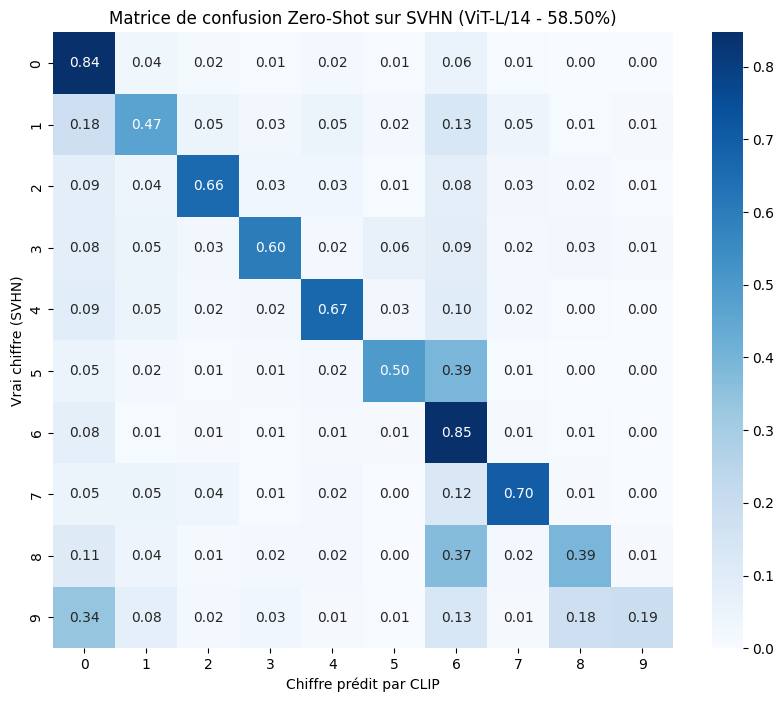

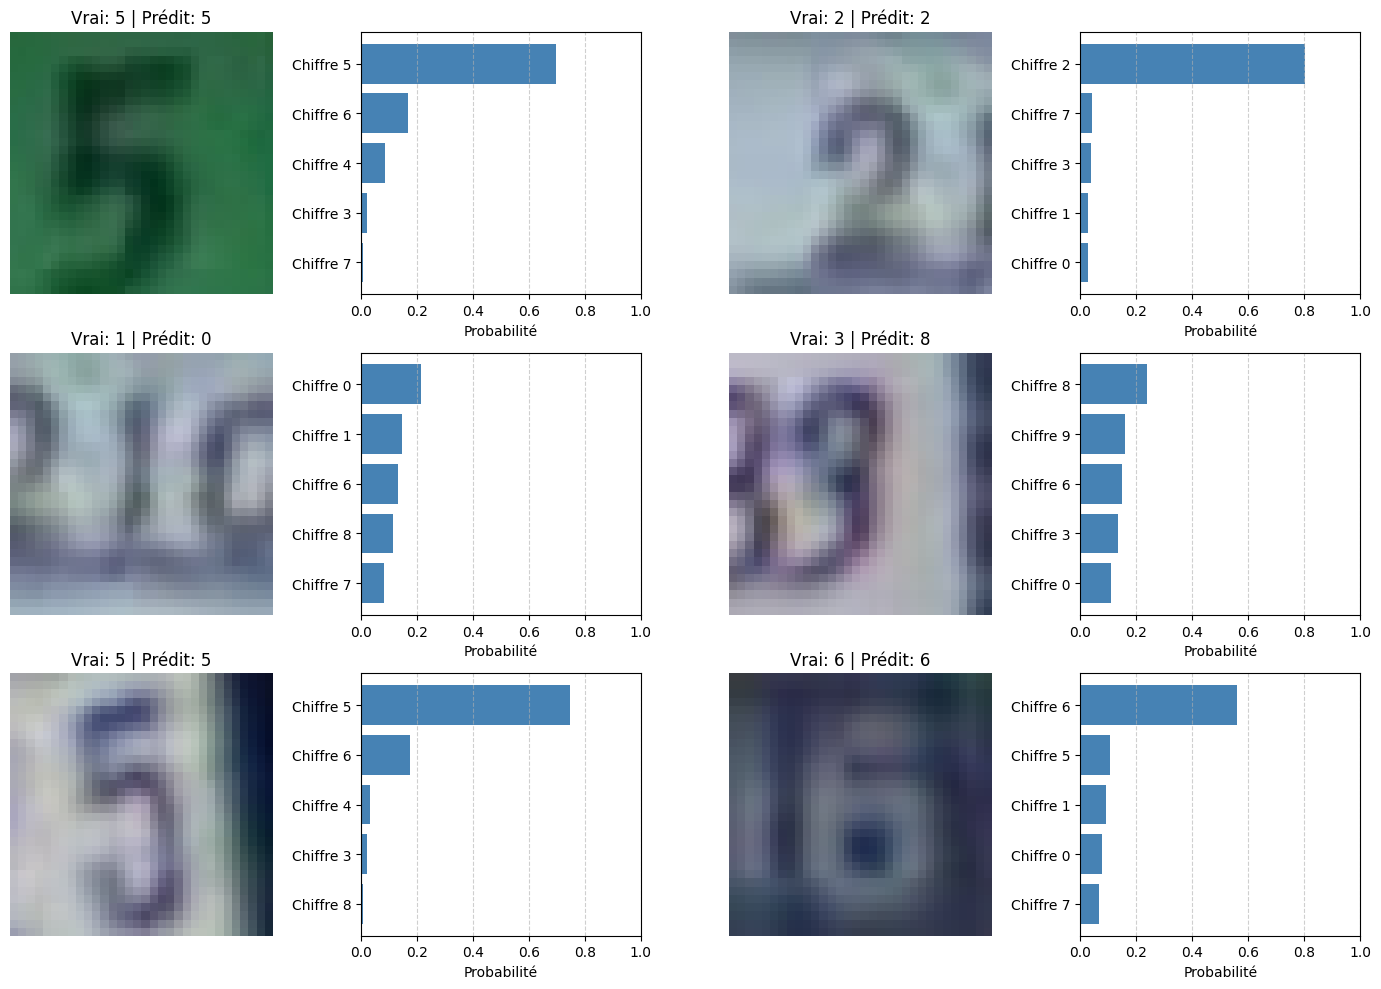

In [6]:
print(f"\n=== Rapport de classification détaillé ({best_model_name}) ===")
print(classification_report(y_test, best_preds, target_names=classes, digits=3))

# Matrice de confusion normalisée
cm = confusion_matrix(y_test, best_preds, normalize='true')
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Chiffre prédit par CLIP")
plt.ylabel("Vrai chiffre (SVHN)")
plt.title(f"Matrice de confusion Zero-Shot sur SVHN ({best_model_name} - {best_acc:.2f}%)")
plt.show()

# Visualisation de 6 exemples (succès et erreurs) comme dans le notebook 1
indices = [0, 1, 2, 10, 25, 42]
plt.figure(figsize=(14, 10))
for idx_plot, idx_img in enumerate(indices):
    plt.subplot(3, 4, 2 * idx_plot + 1)
    plt.imshow(X_test[idx_img])
    plt.title(f"Vrai: {y_test[idx_img]} | Prédit: {best_preds[idx_img]}")
    plt.axis("off")

    plt.subplot(3, 4, 2 * idx_plot + 2)
    top5_idx = np.argsort(best_probs[idx_img])[::-1][:5]
    top5_p = best_probs[idx_img][top5_idx]
    y_pos = np.arange(5)
    plt.barh(y_pos, top5_p, color="steelblue")
    plt.yticks(y_pos, [f"Chiffre {k}" for k in top5_idx])
    plt.gca().invert_yaxis()
    plt.xlim([0, 1])
    plt.xlabel("Probabilité")
    plt.grid(axis="x", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()